# Лабораторна: виявлення AI-текстів (human vs AI)

**Ідея роботи.** Перетворюємо тексти на вектори (FastText), порівнюємо два способи агрегації векторів слів у вектор документа та три класифікатори. Щоб результат був чесним, розбиваємо дані за шаблонами текстів, і однакові шаблони не потрапляють одночасно в train і test.

**План**
1. Підготовка середовища та завантаження даних
2. Очищення й EDA
3. Лематизація (spaCy)
4. Групове розбиття, FastText, Mean Pooling vs TF-IDF Weighted Mean
5. SVM, логістична регресія, KNN
6. Групова крос-валідація
7. t-SNE і матриці помилок

## 0. Налаштування середовища

In [1]:
# Крок 0. Перевіряємо залежності й за потреби доставляємо їх (Colab / Jupyter)
import importlib.util, os, re, subprocess, sys, warnings, zipfile
from pathlib import Path

NEEDED_LIBS = {
    'numpy': 'numpy',
    'pandas': 'pandas',
    'matplotlib': 'matplotlib',
    'seaborn': 'seaborn',
    'sklearn': 'scikit-learn',
    'gensim': 'gensim',
    'spacy': 'spacy',
    'requests': 'requests',
}
absent_libs = [
    pip_name
    for module, pip_name in NEEDED_LIBS.items()
    if importlib.util.find_spec(module) is None
]
if absent_libs:
  print('Доінсталовуємо пакети, яких бракує:', ', '.join(absent_libs))
  subprocess.check_call(
      [sys.executable, '-m', 'pip', 'install', '-q', *absent_libs]
  )
  print(
      'Пакети встановлено. Якщо імпорт не підхопився, перезапустіть'
      ' runtime і виконайте всі комірки.'
  )

warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

RANDOM_STATE = 42  # одне зерно на весь ноутбук
np.random.seed(RANDOM_STATE)
sns.set_theme(style='whitegrid', context='notebook')
print('Версія Python:', sys.version.split()[0])

Доінсталовуємо пакети, яких бракує: gensim
Пакети встановлено. Якщо імпорт не підхопився, перезапустіть runtime і виконайте всі комірки.
Версія Python: 3.13.18


## 1. Завантаження даних
Качаємо CSV з Kaggle (якщо його ще немає локально) і дивимось на структуру таблиці.

In [2]:
# Крок 1. Завантаження датасету з Kaggle (архів із CSV) і перший погляд на таблицю
import requests

DATA_FOLDER = Path('data')
DATA_FOLDER.mkdir(exist_ok=True)
CSV_FILE = DATA_FOLDER / 'ai_vs_human_text_2026.csv'
KAGGLE_URL = 'https://www.kaggle.com/api/v1/datasets/download/alitaqishah/ai-vs-human-text-classification-dataset-2026'

if not CSV_FILE.exists():  # качаємо лише якщо файлу ще немає
  archive_path = DATA_FOLDER / 'dataset.zip'
  http_resp = requests.get(KAGGLE_URL, timeout=120)
  http_resp.raise_for_status()
  archive_path.write_bytes(http_resp.content)
  with zipfile.ZipFile(archive_path) as archive:
    archive.extractall(DATA_FOLDER)
  archive_path.unlink(missing_ok=True)

raw_df = pd.read_csv(CSV_FILE)
print('Розмір вихідної таблиці (рядки, стовпці):', raw_df.shape)
display(raw_df.head())
display(raw_df.dtypes.to_frame('dtype'))

Розмір вихідної таблиці (рядки, стовпці): (2000, 9)


,text_id,label,source_model,domain,text_content,topic_hint,word_count,avg_sentence_length,generation_method
0,TXT_0001,human,human,social,can we talk about gene editing ethics for a se...,gene editing ethics,27,13.5,template+human_variation
1,TXT_0002,human,human,social,update on election integrity concerns: it's co...,election integrity concerns,20,10.0,template+human_variation
2,TXT_0003,ai,gemini-2.0,news,Analysts are closely watching developments rel...,climate change adaptation strategies,39,13.0,style_simulation
3,TXT_0004,human,human,academic,This paper examines genomic research breakthro...,genomic research breakthroughs,49,16.3,template+human_variation
4,TXT_0005,ai,gpt-4o,academic,Existing literature on student debt crisis has...,student debt crisis,42,10.8,style_simulation


,dtype
text_id,object
label,object
source_model,object
domain,object
text_content,object
topic_hint,object
word_count,int64
avg_sentence_length,float64
generation_method,object


## 2. Очищення даних та EDA
Прибираємо пропуски, дублікати й занадто короткі тексти, мітки переводимо в 0 (human) та 1 (AI).

,Що перевіряємо,Результат
0,Усього рядків,2000
1,Порожніх текстів,0
2,Порожніх міток,0
3,Дублікатів рядків повністю,0
4,Дублікатів лише за текстом,1034


Розмір після чистки: (966, 11)

Співвідношення класів:


,count,percent
label,,
human,579,59.94
ai,387,40.06


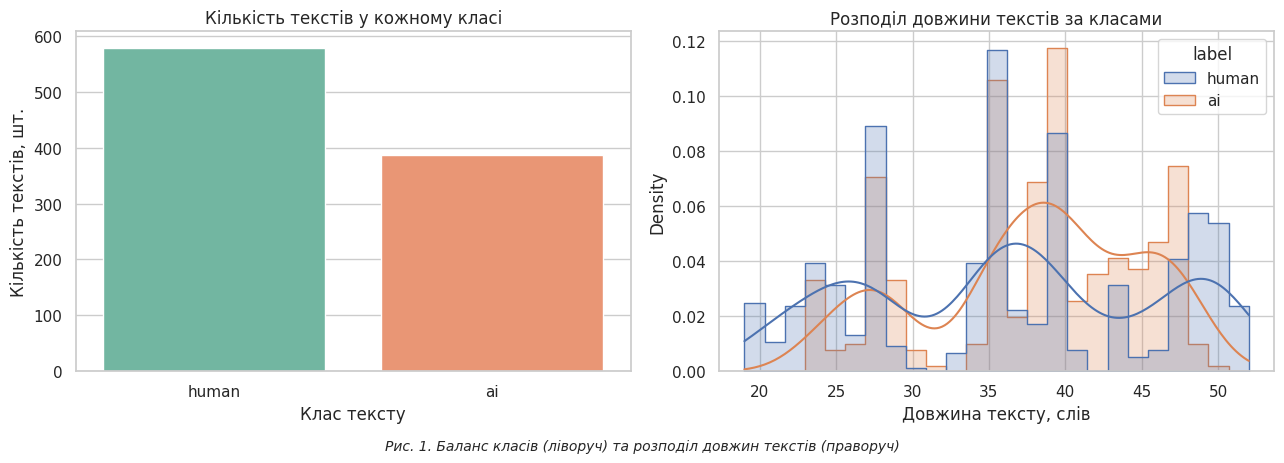

,count,mean,median,std,min,max
label,,,,,,
ai,387,37.93,39.0,7.03,23,50
human,579,36.35,36.0,9.40,19,52


In [3]:
# Крок 2. Перевірка якості даних, очищення та базовий EDA
TEXT_FIELD, LABEL_FIELD = 'text_content', 'label'
needed_cols = {TEXT_FIELD, LABEL_FIELD}
assert needed_cols.issubset(
    raw_df.columns
), f'Не знайдено колонок: {needed_cols - set(raw_df.columns)}'

overview_table = pd.DataFrame({
    'Що перевіряємо': [
        'Усього рядків',
        'Порожніх текстів',
        'Порожніх міток',
        'Дублікатів рядків повністю',
        'Дублікатів лише за текстом',
    ],
    'Результат': [
        len(raw_df),
        raw_df[TEXT_FIELD].isna().sum(),
        raw_df[LABEL_FIELD].isna().sum(),
        raw_df.duplicated().sum(),
        raw_df.duplicated(TEXT_FIELD).sum(),
    ],
})
display(overview_table)

# Чистимо: пропуски, порожні рядки, дублікати та надто короткі тексти (< 3 слів)
texts_df = raw_df.dropna(subset=[TEXT_FIELD, LABEL_FIELD]).copy()
texts_df[TEXT_FIELD] = texts_df[TEXT_FIELD].astype(str).str.strip()
texts_df = (
    texts_df[texts_df[TEXT_FIELD].str.len() > 0]
    .drop_duplicates(subset=[TEXT_FIELD])
    .reset_index(drop=True)
)
texts_df['n_words'] = texts_df[TEXT_FIELD].str.split().str.len()
texts_df = texts_df[texts_df['n_words'] >= 3].reset_index(drop=True)

texts_df['y_label'] = (
    texts_df[LABEL_FIELD].astype(str).str.lower().map({'human': 0, 'ai': 1})
)
assert texts_df['y_label'].notna().all(), 'У даних є мітки, відмінні від human / ai'

print('Розмір після чистки:', texts_df.shape)
print('\nСпіввідношення класів:')
display(
    pd.concat(
        [
            texts_df[LABEL_FIELD].value_counts().rename('count'),
            texts_df[LABEL_FIELD]
            .value_counts(normalize=True)
            .mul(100)
            .round(2)
            .rename('percent'),
        ],
        axis=1,
    )
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.countplot(
    data=texts_df, x=LABEL_FIELD, hue=LABEL_FIELD, palette='Set2', legend=False, ax=axes[0]
)
axes[0].set_title('Кількість текстів у кожному класі')
axes[0].set_xlabel('Клас тексту')
axes[0].set_ylabel('Кількість текстів, шт.')
sns.histplot(
    data=texts_df,
    x='n_words',
    hue=LABEL_FIELD,
    bins=25,
    kde=True,
    element='step',
    stat='density',
    common_norm=False,
    ax=axes[1],
)
axes[1].set_title('Розподіл довжини текстів за класами')
axes[1].set_xlabel('Довжина тексту, слів')
plt.tight_layout()
plt.figtext(0.5, -0.02,
            'Рис. 1. Баланс класів (ліворуч) та розподіл довжин текстів (праворуч)',
            ha='center', fontsize=10, style='italic')
plt.show()

display(
    texts_df.groupby(LABEL_FIELD)['n_words']
    .agg(['count', 'mean', 'median', 'std', 'min', 'max'])
    .round(2)
)

## 3. Попередня обробка тексту
Лематизуємо тексти й викидаємо стоп-слова та не-алфавітні токени.

In [4]:
# Крок 3. Лематизація: перетворюємо кожен текст на список лем
import spacy

try:
  spacy_nlp = spacy.load('en_core_web_sm', disable=['parser', 'ner'])
except OSError:
  print('Модель en_core_web_sm відсутня, завантажую...')
  subprocess.check_call(
      [sys.executable, '-m', 'spacy', 'download', 'en_core_web_sm']
  )
  spacy_nlp = spacy.load('en_core_web_sm', disable=['parser', 'ner'])


def lemmatize_corpus(raw_texts, batch_size=128):
  # Беремо лише алфавітні слова без стоп-слів, у нормальній формі та нижньому регістрі
  collected = []
  for doc in spacy_nlp.pipe(raw_texts, batch_size=batch_size):
    lemmas = [
        t.lemma_.lower()
        for t in doc
        if t.is_alpha and not t.is_stop and t.lemma_.strip()
    ]
    collected.append(lemmas)
  return collected


texts_df['lemmas'] = lemmatize_corpus(texts_df[TEXT_FIELD].tolist())
n_empty_docs = texts_df['lemmas'].str.len().eq(0).sum()
print('Документів без жодної леми після обробки:', n_empty_docs)
texts_df = texts_df[texts_df['lemmas'].str.len() > 0].reset_index(drop=True)
display(texts_df[[TEXT_FIELD, 'lemmas', LABEL_FIELD]].head(5))

Документів без жодної леми після обробки: 0


,text_content,lemmas,label
0,can we talk about gene editing ethics for a se...,"[talk, gene, edit, ethic, sec, feel, like, peo...",human
1,update on election integrity concerns: it's co...,"[update, election, integrity, concern, complic...",human
2,Analysts are closely watching developments rel...,"[analyst, closely, watch, development, relate,...",ai
3,This paper examines genomic research breakthro...,"[paper, examine, genomic, research, breakthrou...",human
4,Existing literature on student debt crisis has...,"[exist, literature, student, debt, crisis, pre...",ai


## 4. Розбиття без витоку та ембединги
Шаблонні тексти групуємо, розбиваємо за групами, тренуємо FastText лише на train і будуємо два варіанти векторів документів.

In [5]:
# Крок 4. Розбиття без витоку (за шаблонами), FastText і два способи агрегації векторів
import re
from gensim.models import FastText
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import StratifiedGroupKFold


def build_template_key(row):
  # Ключ шаблону: тему, числа й дні тижня замінюємо плейсхолдерами. Мітку класу не використовуємо.
  text = str(row[TEXT_FIELD]).lower()
  topic = str(row.get('topic_hint', '')).lower().strip()
  if topic and topic != 'nan':
    text = text.replace(topic, ' <topic> ')
  text = re.sub(r'\b\d+(?:[.,]\d+)?\b', ' <num> ', text)
  text = re.sub(
      r'\b(?:monday|tuesday|wednesday|thursday|friday|saturday|sunday)\b',
      ' <day> ',
      text,
  )
  text = re.sub(r'[^a-z<>]+', ' ', text)
  return ' '.join(text.split())


texts_df['template_key'] = texts_df.apply(build_template_key, axis=1)
row_ids = np.arange(len(texts_df))
y = texts_df['y_label'].to_numpy(dtype=int)
template_ids = texts_df['template_key'].to_numpy()

group_splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
tr_idx, te_idx = next(group_splitter.split(row_ids, y, groups=template_ids))

tr_groups = set(template_ids[tr_idx])
te_groups = set(template_ids[te_idx])
assert tr_groups.isdisjoint(
    te_groups
), 'Витік: однакові шаблони потрапили і в train, і в test'

print('Усього документів:', len(texts_df))
print('Унікальних шаблонів:', texts_df['template_key'].nunique())
print('Розмір train / test:', len(tr_idx), '/', len(te_idx))
print('Шаблонів у train / test:', len(tr_groups), '/', len(te_groups))
print('Спільних шаблонів у train і test:', len(tr_groups & te_groups))
print(
    'Класи в train:',
    pd.Series(y[tr_idx]).value_counts().sort_index().to_dict(),
)
print(
    'Класи в test:', pd.Series(y[te_idx]).value_counts().sort_index().to_dict()
)

train_lemmas = texts_df.iloc[tr_idx]['lemmas'].tolist()
test_lemmas = texts_df.iloc[te_idx]['lemmas'].tolist()
y_tr, y_te = y[tr_idx], y[te_idx]

fasttext_model = FastText(
    sentences=train_lemmas,
    vector_size=100,
    window=5,
    min_count=2,
    sg=1,
    workers=4,
    seed=RANDOM_STATE,
    epochs=20,
)
print('Розмір словника FastText:', len(fasttext_model.wv.key_to_index))

# Документи вже розбиті на леми, тому векторизатор просто приймає готові списки
tfidf_vec = TfidfVectorizer(analyzer=lambda x: x, lowercase=False)
X_sparse_train = tfidf_vec.fit_transform(train_lemmas)
X_sparse_test = tfidf_vec.transform(test_lemmas)
vocab_terms = tfidf_vec.get_feature_names_out()


def average_vectors(lemmas, model):
  # Спосіб 1: звичайне середнє FastText-векторів усіх лем документа
  vectors = [model.wv[t] for t in lemmas]
  return np.mean(vectors, axis=0) if vectors else np.zeros(model.vector_size)


def tfidf_weighted_vectors(token_lists, tfidf_matrix, model, feature_names):
  # Спосіб 2: середнє, у якому внесок кожної леми визначає її вага TF-IDF
  collected = np.zeros((len(token_lists), model.vector_size), dtype=np.float32)
  for row_i in range(tfidf_matrix.shape[0]):
    row = tfidf_matrix.getrow(row_i)
    vectors, weights = [], []
    for col_i, weight in zip(row.indices, row.data):
      token = feature_names[col_i]
      vectors.append(model.wv[token])
      weights.append(weight)
    if vectors:
      collected[row_i] = np.average(vectors, axis=0, weights=np.asarray(weights))
  return collected


X_avg_train = np.vstack([average_vectors(t, fasttext_model) for t in train_lemmas])
X_avg_test = np.vstack([average_vectors(t, fasttext_model) for t in test_lemmas])
X_tw_train = tfidf_weighted_vectors(
    train_lemmas, X_sparse_train, fasttext_model, vocab_terms
)
X_tw_test = tfidf_weighted_vectors(
    test_lemmas, X_sparse_test, fasttext_model, vocab_terms
)

embedding_variants = {
    'Mean Pooling': (X_avg_train, X_avg_test),
    'TF-IDF Weighted Mean': (X_tw_train, X_tw_test),
}
for name, (tr, te) in embedding_variants.items():
  print(
      f'{name}: train={tr.shape}, test={te.shape},'
      f' NaN={np.isnan(tr).sum()+np.isnan(te).sum()}'
  )

Усього документів: 966
Унікальних шаблонів: 34
Розмір train / test: 784 / 182
Шаблонів у train / test: 28 / 6
Спільних шаблонів у train і test: 0
Класи в train: {0: 484, 1: 300}
Класи в test: {0: 95, 1: 87}
Розмір словника FastText: 447
Mean Pooling: train=(784, 100), test=(182, 100), NaN=0
TF-IDF Weighted Mean: train=(784, 100), test=(182, 100), NaN=0


## 5. Порівняння класифікаторів
Кожен із трьох класифікаторів перевіряємо на обох типах ембедингів.

,Агрегація,Класифікатор,F1 macro,Accuracy,Balanced Accuracy,ROC-AUC
0,TF-IDF Weighted Mean,KNN,0.4097,0.4560,0.4693,0.4467
1,TF-IDF Weighted Mean,SVM (RBF),0.3628,0.4890,0.5096,0.3175
2,Mean Pooling,SVM (RBF),0.3234,0.4780,0.5000,0.1962
3,Mean Pooling,KNN,0.3184,0.4670,0.4885,0.4479
4,TF-IDF Weighted Mean,Logistic Regression,0.3036,0.4066,0.4243,0.4031
5,Mean Pooling,Logistic Regression,0.3027,0.4341,0.4540,0.3304


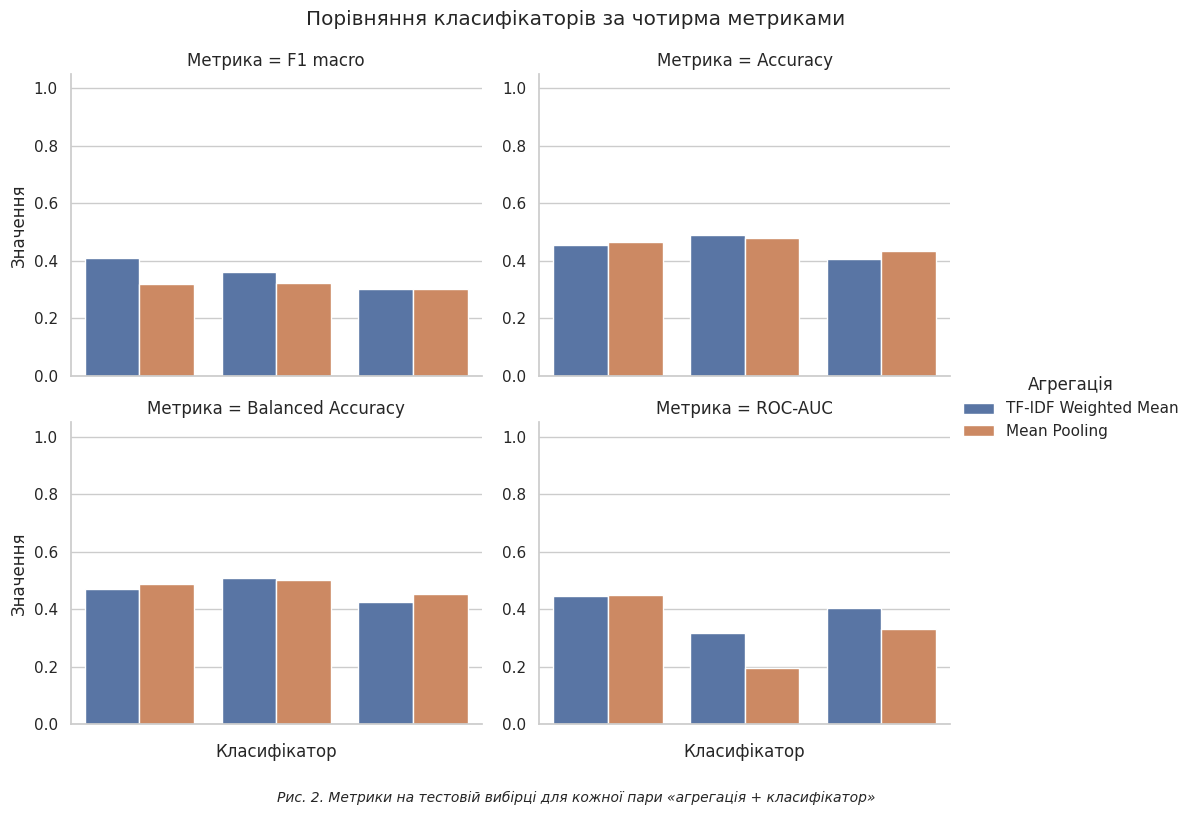

In [6]:
# Крок 5. Три класифікатори на двох типах ембедингів (один hold-out фолд)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    roc_auc_score,
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

classifier_zoo = {
    'SVM (RBF)': SVC(kernel='rbf', probability=True, random_state=RANDOM_STATE),
    'Logistic Regression': LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    'KNN': KNeighborsClassifier(n_neighbors=5),
}

result_rows, fitted_pipes, preds_store = [], {}, {}
for variant_name, (X_train, X_test) in embedding_variants.items():
  for model_name, base_clf in classifier_zoo.items():
    clf_pipe = make_pipeline(StandardScaler(), base_clf)
    clf_pipe.fit(X_train, y_tr)
    y_pred = clf_pipe.predict(X_test)
    proba_pos = clf_pipe.predict_proba(X_test)[:, 1]
    fitted_pipes[(variant_name, model_name)] = clf_pipe
    preds_store[(variant_name, model_name)] = y_pred
    result_rows.append({
        'Агрегація': variant_name,
        'Класифікатор': model_name,
        'F1 macro': f1_score(y_te, y_pred, average='macro'),
        'Accuracy': accuracy_score(y_te, y_pred),
        'Balanced Accuracy': balanced_accuracy_score(y_te, y_pred),
        'ROC-AUC': roc_auc_score(y_te, proba_pos),
    })

benchmark_table = (
    pd.DataFrame(result_rows)
    .sort_values(['F1 macro', 'ROC-AUC'], ascending=False)
    .reset_index(drop=True)
)
display(
    benchmark_table.style.format({
        c: '{:.4f}'
        for c in ['F1 macro', 'Accuracy', 'Balanced Accuracy', 'ROC-AUC']
    }).background_gradient(
        subset=['F1 macro', 'Accuracy', 'Balanced Accuracy', 'ROC-AUC'],
        cmap='YlGn',
    )
)
benchmark_table.to_csv('model_comparison.csv', index=False)

# Для барчарту переводимо таблицю в довгий формат
metrics_long = benchmark_table.melt(
    id_vars=['Агрегація', 'Класифікатор'],
    var_name='Метрика',
    value_name='Значення',
)
facet_grid = sns.catplot(
    data=metrics_long,
    x='Класифікатор',
    y='Значення',
    hue='Агрегація',
    col='Метрика',
    kind='bar',
    col_wrap=2,
    height=4,
    aspect=1.25,
    sharey=False,
)
facet_grid.set_xticklabels(rotation=20)
facet_grid.set(ylim=(0, 1.05))
facet_grid.fig.subplots_adjust(top=0.9)
facet_grid.fig.suptitle('Порівняння класифікаторів за чотирма метриками')
facet_grid.fig.text(0.5, -0.01,
                   'Рис. 2. Метрики на тестовій вибірці для кожної пари «агрегація + класифікатор»',
                   ha='center', fontsize=10, style='italic')
plt.show()

## 6. Групова крос-валідація
Повторюємо весь пайплайн (FastText, TF-IDF, класифікатори) на кожному з 5 фолдів, щоб побачити розкид метрик.

In [7]:
# Крок 6. Групова крос-валідація (5 фолдів): перевіряємо, чи стабільні результати
from sklearn.base import clone

cv_records = []  # сюди збираємо метрики кожного фолду
group_cv_splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

for fold_no, (cv_train_idx, cv_test_idx) in enumerate(
    group_cv_splitter.split(row_ids, y, template_ids), start=1
):
  assert set(template_ids[cv_train_idx]).isdisjoint(set(template_ids[cv_test_idx]))
  cv_train_tokens = texts_df.iloc[cv_train_idx]['lemmas'].tolist()
  cv_test_tokens = texts_df.iloc[cv_test_idx]['lemmas'].tolist()
  cv_y_train, cv_y_test = y[cv_train_idx], y[cv_test_idx]

  cv_ft = FastText(
      sentences=cv_train_tokens,
      vector_size=100,
      window=5,
      min_count=2,
      sg=1,
      workers=1,
      seed=RANDOM_STATE,
      epochs=20,
  )
  cv_tfidf = TfidfVectorizer(analyzer=lambda x: x, lowercase=False)
  cv_sparse_train = cv_tfidf.fit_transform(cv_train_tokens)
  cv_sparse_test = cv_tfidf.transform(cv_test_tokens)
  cv_features = cv_tfidf.get_feature_names_out()

  cv_mean_train = np.vstack(
      [average_vectors(t, cv_ft) for t in cv_train_tokens]
  )
  cv_mean_test = np.vstack(
      [average_vectors(t, cv_ft) for t in cv_test_tokens]
  )
  cv_weighted_train = tfidf_weighted_vectors(
      cv_train_tokens, cv_sparse_train, cv_ft, cv_features
  )
  cv_weighted_test = tfidf_weighted_vectors(
      cv_test_tokens, cv_sparse_test, cv_ft, cv_features
  )

  cv_representations = {
      'Mean Pooling': (cv_mean_train, cv_mean_test),
      'TF-IDF Weighted Mean': (cv_weighted_train, cv_weighted_test),
  }
  for variant_name, (cv_X_train, cv_X_test) in cv_representations.items():
    for model_name, base_clf in classifier_zoo.items():
      cv_pipe = make_pipeline(StandardScaler(), clone(base_clf))
      cv_pipe.fit(cv_X_train, cv_y_train)
      cv_pred = cv_pipe.predict(cv_X_test)
      cv_score = cv_pipe.predict_proba(cv_X_test)[:, 1]
      cv_records.append({
          'Fold': fold_no,
          'Агрегація': variant_name,
          'Класифікатор': model_name,
          'F1 macro': f1_score(cv_y_test, cv_pred, average='macro'),
          'Accuracy': accuracy_score(cv_y_test, cv_pred),
          'Balanced Accuracy': balanced_accuracy_score(cv_y_test, cv_pred),
          'ROC-AUC': roc_auc_score(cv_y_test, cv_score),
      })

cv_fold_table = pd.DataFrame(cv_records)
# Усереднюємо метрики по фолдах
cv_overview = (
    cv_fold_table.groupby(['Агрегація', 'Класифікатор'])
    .agg(
        F1_mean=('F1 macro', 'mean'),
        F1_std=('F1 macro', 'std'),
        Accuracy_mean=('Accuracy', 'mean'),
        Balanced_Accuracy_mean=('Balanced Accuracy', 'mean'),
        ROC_AUC_mean=('ROC-AUC', 'mean'),
    )
    .reset_index()
    .sort_values('F1_mean', ascending=False)
)
display(
    cv_overview.style.format({c: '{:.4f}' for c in cv_overview.columns[2:]})
)
cv_fold_table.to_csv('grouped_cv_folds.csv', index=False)
cv_overview.to_csv('grouped_cv_overview.csv', index=False)

,Агрегація,Класифікатор,F1_mean,F1_std,Accuracy_mean,Balanced_Accuracy_mean,ROC_AUC_mean
5,TF-IDF Weighted Mean,SVM (RBF),0.4763,0.1635,0.5116,0.5638,0.5359
4,TF-IDF Weighted Mean,Logistic Regression,0.4261,0.1540,0.4578,0.5054,0.3852
3,TF-IDF Weighted Mean,KNN,0.4239,0.0557,0.4507,0.4955,0.5315
0,Mean Pooling,KNN,0.4101,0.1468,0.4528,0.5262,0.5336
2,Mean Pooling,SVM (RBF),0.3947,0.1590,0.4618,0.5383,0.4758
1,Mean Pooling,Logistic Regression,0.3356,0.1157,0.4161,0.4872,0.2938


## 7. Візуалізація
t-SNE показує, наскільки класи розділені в просторі ембедингів, а матриці помилок показують, де саме моделі помиляються.

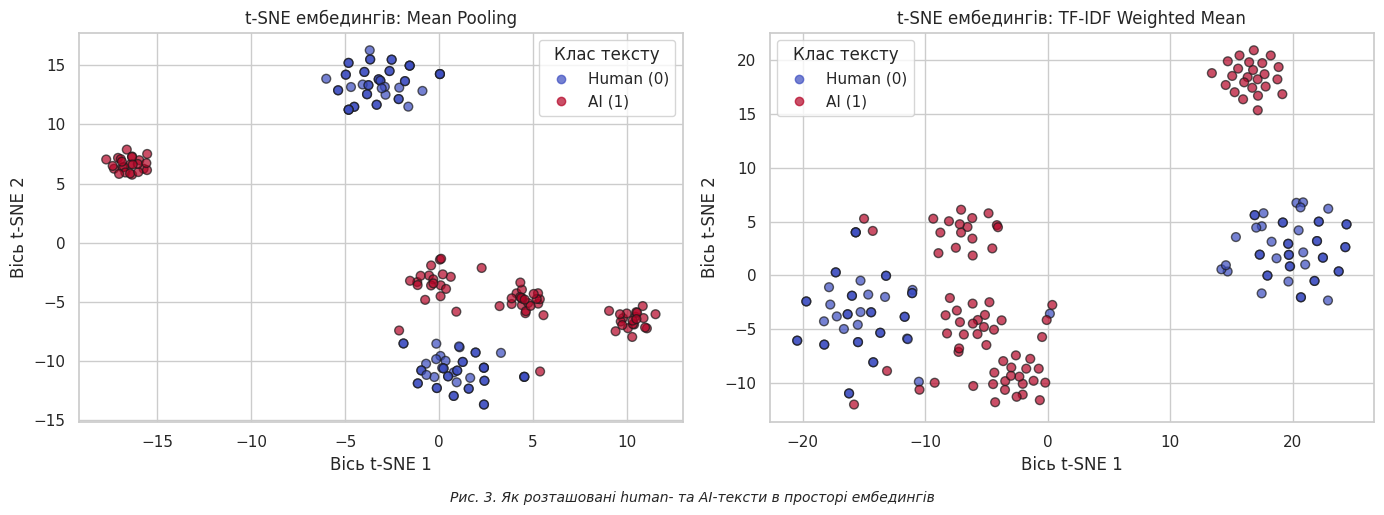

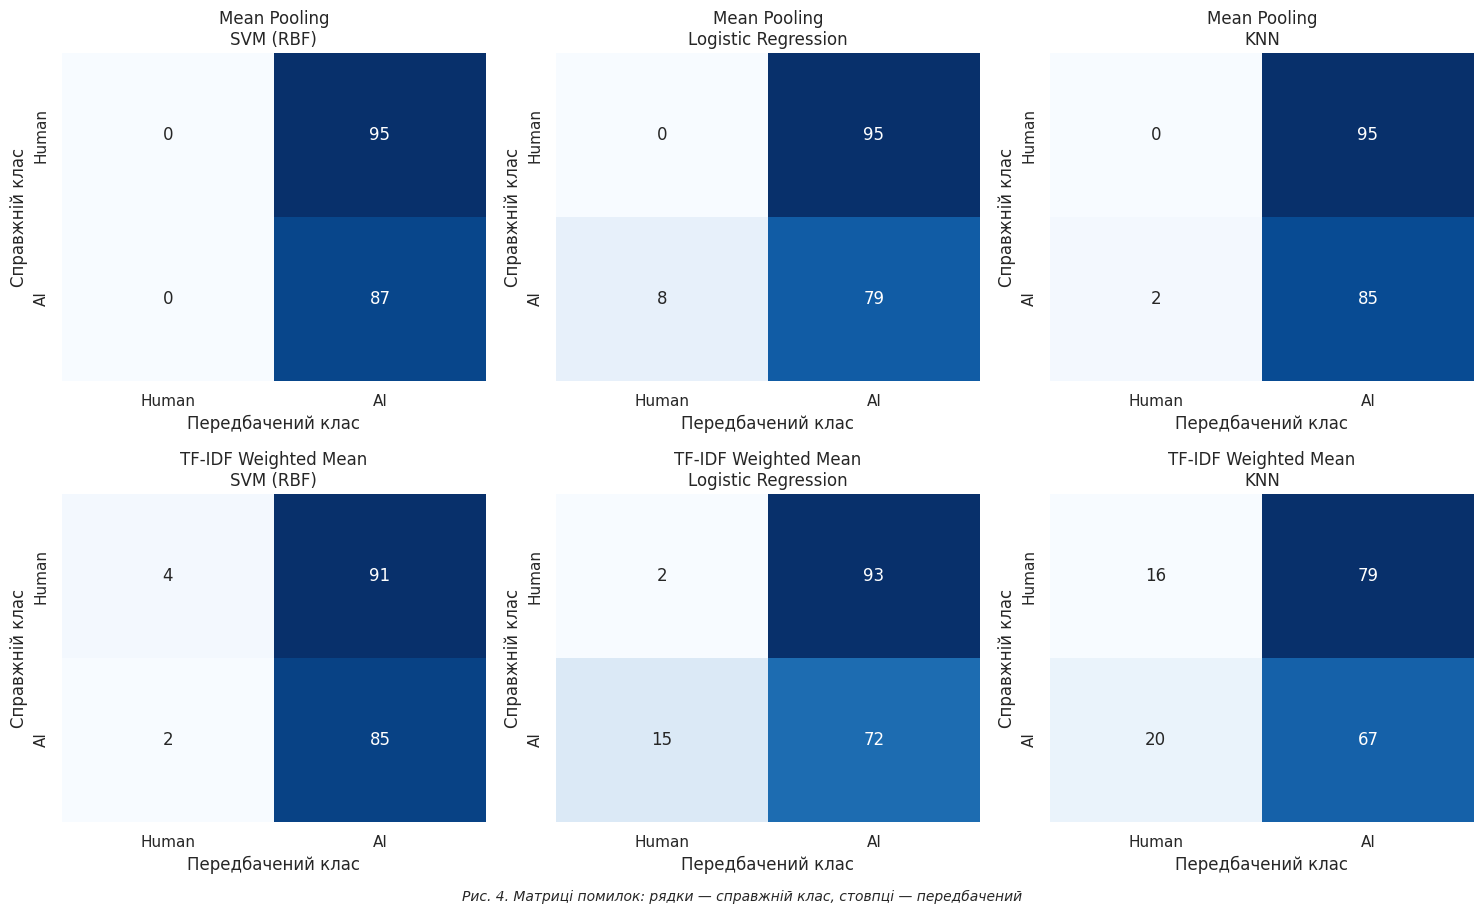

In [8]:
# Крок 7. Візуалізація: t-SNE ембедингів і матриці помилок
from sklearn.manifold import TSNE

# (а) Проєкція тестових ембедингів у 2D методом t-SNE
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
tsne_proj = TSNE(n_components=2, random_state=RANDOM_STATE, perplexity=30)

for ax, (variant_name, (X_tr, X_te)) in zip(axes, embedding_variants.items()):
  X_std = StandardScaler().fit_transform(X_te)
  X_2d = tsne_proj.fit_transform(X_std)
  pts = ax.scatter(
      X_2d[:, 0],
      X_2d[:, 1],
      c=y_te,
      cmap='coolwarm',
      alpha=0.7,
      edgecolors='k',
      s=40,
  )
  ax.set_title(f't-SNE ембедингів: {variant_name}')
  ax.set_xlabel('Вісь t-SNE 1')
  ax.set_ylabel('Вісь t-SNE 2')
  handles, _ = pts.legend_elements()
  ax.legend(handles, ['Human (0)', 'AI (1)'], title='Клас тексту')

plt.tight_layout()
plt.figtext(0.5, -0.02,
            'Рис. 3. Як розташовані human- та AI-тексти в просторі ембедингів',
            ha='center', fontsize=10, style='italic')
plt.show()

# (б) Матриці помилок для всіх шести комбінацій
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
variant_order = ['Mean Pooling', 'TF-IDF Weighted Mean']
model_order = ['SVM (RBF)', 'Logistic Regression', 'KNN']

for row_i, variant_name in enumerate(variant_order):
  for col_i, model_name in enumerate(model_order):
    ax = axes[row_i, col_i]
    y_pred = preds_store[(variant_name, model_name)]
    conf_mat = confusion_matrix(y_te, y_pred)
    sns.heatmap(
        conf_mat,
        annot=True,
        fmt='d',
        cmap='Blues',
        cbar=False,
        ax=ax,
        xticklabels=['Human', 'AI'],
        yticklabels=['Human', 'AI'],
    )
    ax.set_title(f'{variant_name}\n{model_name}')
    ax.set_xlabel('Передбачений клас')
    ax.set_ylabel('Справжній клас')

plt.tight_layout()
plt.figtext(0.5, -0.01,
            'Рис. 4. Матриці помилок: рядки — справжній клас, стовпці — передбачений',
            ha='center', fontsize=10, style='italic')
plt.show()
